In [33]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad=0.0
        self._backward=lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # we want to set out backward to be the function that propagate the gradient
        out=Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad=1.0 * out.grad
            other.grad=1.0 * out.grad
        out._backward=_backward
        
        return out
        

    def __mul__(self, other):
        out=Value(self.data * other.data, (self, other), '*')
        def _backward():
            # chain rule
            self.grad=other.data * out.grad
            self.other=self.data * out.grad
        out._backward=_backward
        return out
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t, (self,), 'tanh')
        def _backward():
            # chain rule
            self.grad= (1-t**2)*out.grad
        out._backward=_backward
        return out
        

In [3]:
# Visualizing the expression graph
from graphviz import Digraph

In [14]:
from graphviz import Digraph

def trace(root):
    """Walk backwards from root, collecting every node and edge."""
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # left to right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # a box showing the label and the value
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # a small extra node for the operation (+ or *)
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect the child to the operation node of its parent
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')

e = a * b;  e.label = 'e'
d = e + c;  d.label = 'd'
f=Value(-2.0, label='f')
L=d*f; L.label='L'

dot = draw_dot(d)
# dot.render('graph', view=True)   # writes graph.svg and opens it
# In Jupyter, just end the cell with:  draw_dot(d)
L

Value(data=-8.0)

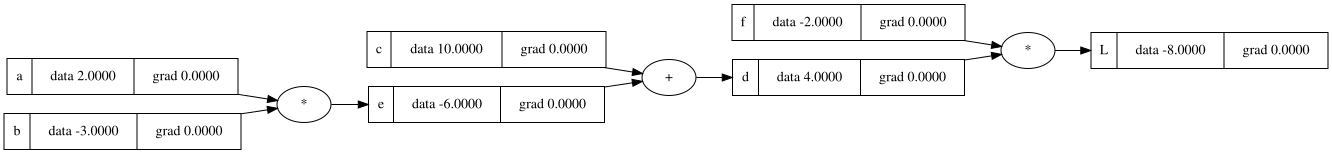

In [15]:
draw_dot(L)

# 00:32:10 manual backpropagation example #1: simple expression

grad==0.0 initially means, the derivative of L with respect to [c, e, d, f]

In [33]:
L.grad=1.0
# dL/df
# L=d*f
# dL/dd=f=-2.0
# dL/df=2*(-3.0) + 10=4
d.grad=2.0
f.grad=4
dL/de=?
we know how L changed with respect to d and f, but not how it did so wrt to e and f directly, but there is a relationship between d and e, itmeans e got to be related to L

de/dd?
dL/de=yes
dL/de?
dL/de=dL/de * de/dd
# same thing applies by symmetry

SyntaxError: cannot assign to expression (2995469354.py, line 8)

In [16]:
# starting from L, if change L with a tiny amount h, how much does L, change?
# changes by h, its propotional and ther derivative will eb one


def lol():
    h=0.001
    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f;  L.label='L'
    L1=L.data

    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f;  L.label='L'
    L2=L.data +h

    print((L2-L1)/h)
# lol()
# derivative of a with respect to L   becuae a is the one we bump by h

In [40]:
lol()

1.000000000000334


In [17]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

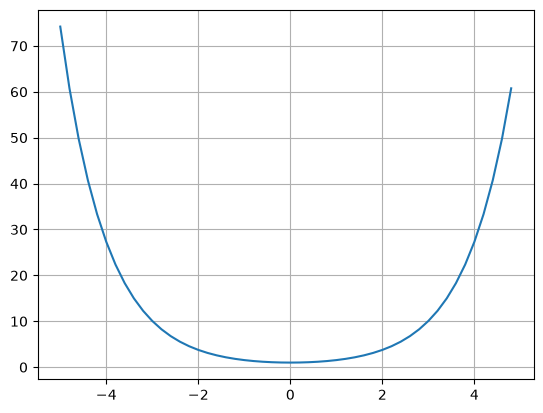

In [5]:
# reak backpropagation

plt.plot(np.arange(-5, 5, 0.2), np.cosh(np.arange(-5, 5, 0.2))); plt.grid();

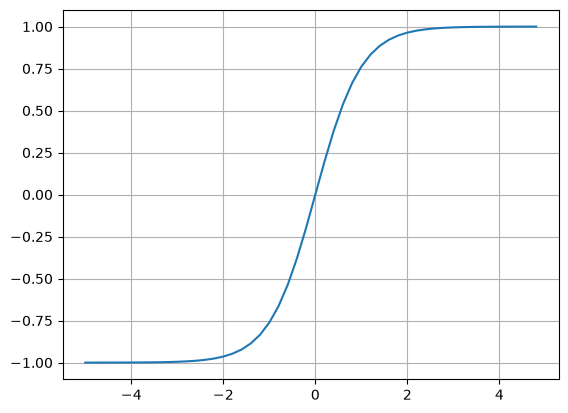

In [22]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

In [34]:
x1=Value(2.0, label='x1')
x2=Value(0.0, label='x2')
#  weigghts [w1, w2]
w1=Value(-3.0, label='w1')
w2=Value(1.0,  label='w2')
# biase of the neuron:
b=Value(6.88137335070195432, label='b')
# x1w1 + x2w2 + b
x1w1=x1*w1;  x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1 + x2w2; x1w1x2w2.label='x1w1x2w2'
n=x1w1x2w2 + b; n.label='n'
o=n.tanh(); o.label="o"


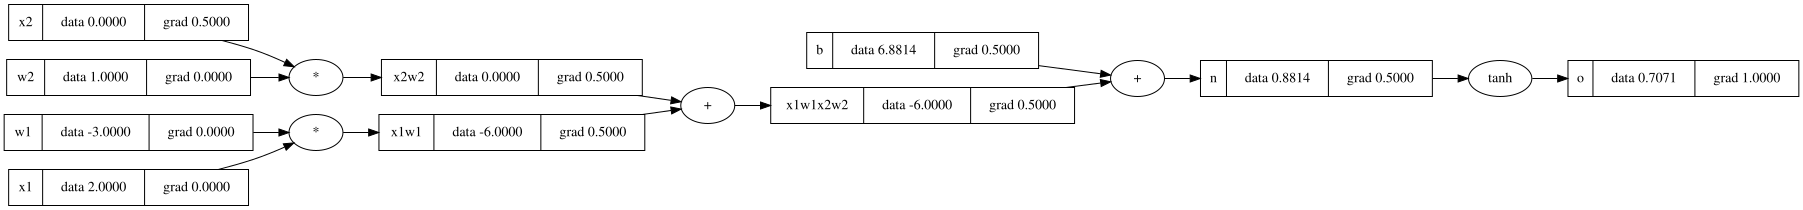

In [46]:
draw_dot(o)

In [35]:
o.grad=1.0


In [36]:
o._backward()

In [39]:
n._backward()

In [41]:
b._backward()

In [43]:
x1w1x2w2._backward()

In [45]:
x2w2._backward()

In [ ]:
x1w1._backward*(

In [61]:
# calculate the gradient of x2, w2, x1, w1
# chain rule in practice
x2.grad=w2.data * x2w2.grad
w2.grad=x2.data * x2w2.grad

In [52]:
x1w1.grad=0.5
x2w2.grad=0.5

In [50]:
x1w1x2w2.grad=0.5
b.grad=0.5

In [49]:
# lets know the local derivative of tanhx
# o=tanh(n)
n.grad=0.5
o.grad=1.0



# do/dn=1-tanh(n)**2
# 1-n**2
o.data
1-o.data**2


# A plus is just a distributor of gradient __  so after the  "+" 
# symbo,distributor,  do/dn=0.5, so distributing to x2w2 and x1w1 will be
#  1*do/dn=0.5 and 1* do/dn=0.5, 1 is as result of 1=dn/dx1w1x2w2 and so on..

# so x1w1x2w2.grad=0.5
# same for  b.grad=0.5
# same distribution law for: x1w1 and x2w2
# pluses are favorite to backprop through because they are simple

0.5000001671017833